In [1]:
import os
import json
import time
import zipfile
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

SEED = 123
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
dataset_path = None

search_roots = [
    "/content/kyc_data",
    "/content/drive/MyDrive"
]

zip_candidates = []

for base in search_roots:
    if not os.path.exists(base):
        continue

    for root, dirs, files in os.walk(base):
        dirs[:] = [d for d in dirs if not d.startswith(".")]

        folder_names = {d.lower() for d in dirs}

        if {"fake", "original"}.issubset(folder_names):
            dataset_path = root
            break

        for filename in files:
            if filename.lower().endswith(".zip"):
                if "kyc" in filename.lower():
                    zip_candidates.append(os.path.join(root, filename))

    if dataset_path:
        break

print("Dataset path:", dataset_path)
print("KYC ZIP files:", zip_candidates)

Dataset path: None
KYC ZIP files: ['/content/drive/MyDrive/KYC DATASET.zip']


In [4]:
if dataset_path is None:
    if not zip_candidates:
        raise FileNotFoundError(
            "Dataset not found. Check the Colab Files panel "
            "and confirm that your KYC ZIP is uploaded."
        )

    zip_path = zip_candidates[0]
    extract_dir = "/content/kyc_data"

    os.makedirs(extract_dir, exist_ok=True)

    if not zipfile.is_zipfile(zip_path):
        raise ValueError(
            f"The file is not a valid ZIP archive: {zip_path}"
        )

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_dir)

    for root, dirs, files in os.walk(extract_dir):
        if {"fake", "original"}.issubset(
            {d.lower() for d in dirs}
        ):
            dataset_path = root
            break

if dataset_path is None:
    raise FileNotFoundError(
        "Could not find both Fake and Original class folders."
    )

print("Using dataset:", dataset_path)
print("Class folders:", os.listdir(dataset_path))

Using dataset: /content/kyc_data/KYC DATASET
Class folders: ['Fake', 'Original']


In [5]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 15

train_raw = keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

holdout_raw = keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_raw.class_names

print("Classes:", class_names)
print("Class mapping:", {name: i for i, name in enumerate(class_names)})

if len(class_names) != 2:
    raise ValueError("This code requires exactly two classes.")

Found 200 files belonging to 2 classes.
Using 140 files for training.
Found 200 files belonging to 2 classes.
Using 60 files for validation.
Classes: ['Fake', 'Original']
Class mapping: {'Fake': 0, 'Original': 1}


In [6]:
holdout_batches = tf.data.experimental.cardinality(
    holdout_raw
).numpy()

if holdout_batches < 2:
    raise ValueError("Not enough holdout batches. Reduce BATCH_SIZE.")

val_batches = holdout_batches // 2

val_raw = holdout_raw.take(val_batches)
test_raw = holdout_raw.skip(val_batches)

print(
    "Training batches:",
    tf.data.experimental.cardinality(train_raw).numpy()
)
print(
    "Validation batches:",
    tf.data.experimental.cardinality(val_raw).numpy()
)
print(
    "Test batches:",
    tf.data.experimental.cardinality(test_raw).numpy()
)

Training batches: 9
Validation batches: 2
Test batches: 2


In [7]:
AUTOTUNE = tf.data.AUTOTUNE

def prepare_xception(images, labels):
    images = preprocess_input(tf.cast(images, tf.float32))
    return images, labels

train_ds = train_raw.map(
    prepare_xception,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds = val_raw.map(
    prepare_xception,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds = test_raw.map(
    prepare_xception,
    num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("Xception preprocessing completed.")

Xception preprocessing completed.


In [8]:
base_model = Xception(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

data_augmentation = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.05)
])

inputs = keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 7, 7, 2048)     │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,394,473 (81.61 MB)

 Trainable params: 528,897 (2.02 MB)

 Non-trainable params: 20,865,576 (79.60 MB)

In [9]:
output_dir = "/content/drive/MyDrive/KYC_Phase2"
os.makedirs(output_dir, exist_ok=True)

model_path = os.path.join(
    output_dir,
    "kyc_xception_best.keras"
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

training_time = time.time() - start_time

print(f"Training time: {training_time / 60:.2f} minutes")
print("Saved model:", model_path)

Epoch 1/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5277 - loss: 0.7624
Epoch 1: val_loss improved from None to 0.72499, saving model to /content/drive/MyDrive/KYC_Phase2/kyc_xception_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/KYC_Phase2/kyc_xception_best.keras
9/9 ━━━━━━━━━━━━━━━━━━━━ 53s 5s/step - accuracy: 0.5143 - loss: 0.7544 - val_accuracy: 0.0000e+00 - val_loss: 0.7250
Epoch 2/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5346 - loss: 0.7071
Epoch 2: val_loss improved from 0.72499 to 0.72227, saving model to /content/drive/MyDrive/KYC_Phase2/kyc_xception_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/KYC_Phase2/kyc_xception_best.keras
9/9 ━━━━━━━━━━━━━━━━━━━━ 49s 5s/step - accuracy: 0.5429 - loss: 0.7164 - val_accuracy: 0.0000e+00 - val_loss: 0.7223
Epoch 3/15
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.4999 - loss: 0.7218
Epoch 3: val_loss improved from 0.72227 to 0.71303, saving model to /content/drive/MyDri

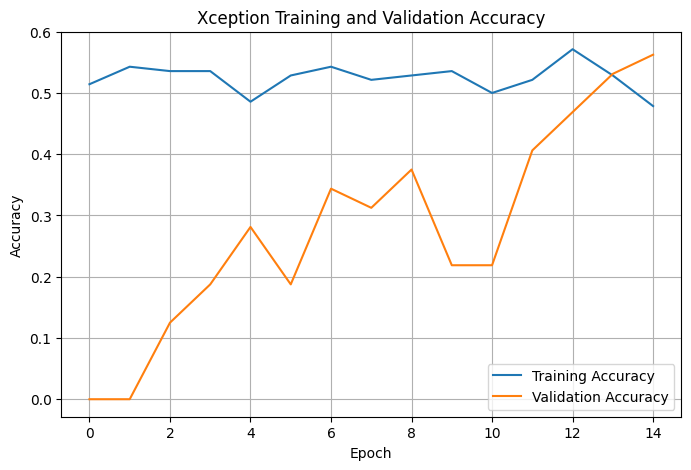

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Xception Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(output_dir, "xception_accuracy.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

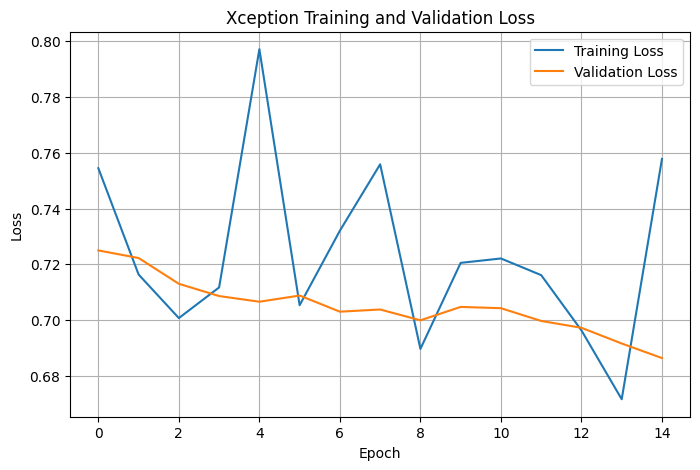

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Xception Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(output_dir, "xception_loss.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
model = keras.models.load_model(model_path)

y_true = []
y_prob = []

for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0).ravel()
    y_prob.extend(probabilities)
    y_true.extend(labels.numpy().ravel().astype(int))

y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

fake_index = class_names.index("Fake") if "Fake" in class_names else None

if fake_index is None:
    raise ValueError(f"Fake class not found. Classes: {class_names}")

# Treat Fake as the positive class for precision, recall and F1
y_true_fake = (y_true == fake_index).astype(int)
y_pred_fake = (y_pred == fake_index).astype(int)

accuracy = accuracy_score(y_true_fake, y_pred_fake)
precision = precision_score(y_true_fake, y_pred_fake, zero_division=0)
recall = recall_score(y_true_fake, y_pred_fake, zero_division=0)
f1 = f1_score(y_true_fake, y_pred_fake, zero_division=0)

print("========== XCEPTION TEST RESULTS ==========")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"Training time: {training_time / 60:.2f} minutes")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

========== XCEPTION TEST RESULTS ==========
Accuracy:  0.2143
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
Training time: 14.89 minutes

Classification Report:
              precision    recall  f1-score   support

        Fake       0.00      0.00      0.00         0
    Original       1.00      0.21      0.35        28

    accuracy                           0.21        28
   macro avg       0.50      0.11      0.18        28
weighted avg       1.00      0.21      0.35        28



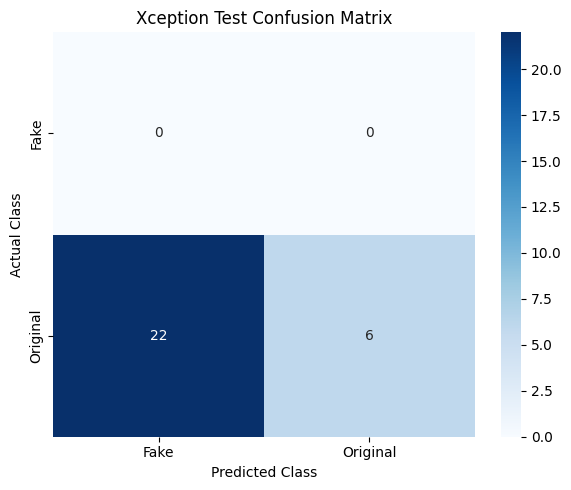

In [13]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Xception Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(output_dir, "xception_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [14]:
results = {
    "model": "Xception",
    "classes": class_names,
    "epochs_completed": len(history.history["loss"]),
    "test_accuracy": float(accuracy),
    "fake_precision": float(precision),
    "fake_recall": float(recall),
    "fake_f1_score": float(f1),
    "training_time_minutes": float(training_time / 60),
    "confusion_matrix": cm.tolist()
}

results_path = os.path.join(
    output_dir,
    "xception_results.json"
)

with open(results_path, "w") as f:
    json.dump(results, f, indent=2)

print("Xception results saved to:", results_path)
print("All outputs are in:", output_dir)

Xception results saved to: /content/drive/MyDrive/KYC_Phase2/xception_results.json
All outputs are in: /content/drive/MyDrive/KYC_Phase2
